# 03 · The models being compared

> Part of the DeepGraph-GBM walk-through. The project is a **benchmark**: it tests whether spatial graph neural networks improve supervised niche prediction in glioblastoma Visium data over matched graph-free models (they do not). See `docs/00_overview_and_roadmap.md`. Notebooks read `data/` (see `docs/WORKFLOW.md`, step A) and the tracked `results/`; none of them trains a model.

Two graph encoders (GraphSAGE, GAT) are compared with three graph-free models (logistic regression, MLP,
MLP + neighbour-averaged features). This notebook instantiates the neural models, shows the multi-task
heads, and looks at the hyperparameters each family chose in the leave-one-patient-out search.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()          # run from notebooks/
PRE = REPO / "data" / "preprocessed"
RES = REPO / "results"
NICHES = ["immune_cold", "immune_hot", "normal", "necrotic"]
COLORS = {"immune_cold": "#D55E00", "immune_hot": "#0072B2", "normal": "#009E73",
          "necrotic": "#CC79A7", "exclude": "#DDDDDD"}
pd.set_option("display.precision", 3)
import torch
from deepgraph_gbm.models.multitask import DeepGraphGBM, multitask_loss
from deepgraph_gbm.models.baselines import MLPBaseline

## 1. Architectures and sizes

In [2]:
n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
sage = DeepGraphGBM(in_dim=3000, encoder_type="graphsage")
gat = DeepGraphGBM(in_dim=3000, encoder_type="gat", gat_heads=4)
mlp = MLPBaseline(in_dim=3000)
pd.DataFrame([
    {"model": "GraphSAGE + heads", "aggregation": "mean over neighbours", "parameters": f"{n_params(sage):,}"},
    {"model": "GAT + heads", "aggregation": "4-head attention over neighbours", "parameters": f"{n_params(gat):,}"},
    {"model": "MLP (niche head)", "aggregation": "none: each spot alone", "parameters": f"{n_params(mlp):,}"},
])

,model,aggregation,parameters
0,GraphSAGE + heads,mean over neighbours,"1,751,815"
1,GAT + heads,4-head attention over neighbours,"985,863"
2,MLP (niche head),none: each spot alone,"868,869"


All encoders map 3,000 genes to a 128-dimensional embedding (3000 → 256 → 256 → 128), with batch
normalisation, ReLU and dropout. GAT has fewer parameters because its hidden layers concatenate four heads
of width d/4. `GATConv` also applies dropout to its attention coefficients, a mild extra regulariser that
the paper discloses. Logistic regression (scikit-learn) and MLP + neighbours are built inside
`scripts/15_revision_benchmark.py`.

## 2. One forward pass, three heads

In [3]:
g = torch.load(PRE / "graphs.pt", weights_only=False)[0]
sage.eval()
with torch.no_grad():
    out = sage(g.x, g.edge_index)
    loss, parts = multitask_loss(out, g.niche_y, g.mes_y, g.risk_y)
print(f"section {g.section}: {g.n_spots:,} spots")
print({k: tuple(v.shape) for k, v in out.items()})
print("untrained loss components:", {k: round(float(v), 3) for k, v in parts.items()}, "| total", round(float(loss), 3))

section SNU16A: 4,712 spots
{'z': (4712, 128), 'niche_logits': (4712, 4), 'mes_prob': (4712,), 'risk': ()}
untrained loss components: {'niche': 1.375, 'mes': 0.689, 'survival': 0.317} | total 1.878


The heads are a niche classifier (4 logits), an MES head (sigmoid), and a slide-level risk head
(attention pooling, trained on a rule-derived "pseudo-risk").

* **Fixed-split models** (Table 1, Figures 1–3) use all three heads:
  1.0·CE(niche) + 0.5·BCE(MES) + 0.5·MSE(risk).
* **LOPO and UKF benchmarks** use only the niche and MES heads.
* **The slide head does not work.** On held-out sections, its predictions do not track its own training
  target (r = 0.40, −0.80, 0.08 across seeds; `results/tables/main/slide_risk_head_eval.csv`). No result
  depends on it.

In [4]:
pd.read_csv(RES / "tables" / "main" / "slide_risk_head_eval.csv")

,seed,n_sections,pearson_r,pearson_p,spearman_rho,spearman_p,rmse
0,7,5,0.401,0.504,0.3,0.624,0.726
1,42,5,-0.804,0.101,-0.4,0.505,0.515
2,123,5,0.079,0.899,0.3,0.624,0.361


## 3. What did each family choose under an equal tuning budget?

Each family sampled 8 configurations from a shared grid. The best one was chosen *per fold* on validation
patients.

In [5]:
cc = json.load(open(RES / "revision" / "revision_summary.json"))["chosen_configs"]
rows = []
for fam in ("sage", "gat", "mlp", "mlpnbr"):
    for fold, c in cc[fam].items():
        rows.append({"family": fam, "fold": fold, **c})
chosen = pd.DataFrame(rows)
print("GraphSAGE neighbourhood size k chosen per fold:", chosen[chosen.family == "sage"].k.value_counts().to_dict())
print("GraphSAGE depth chosen per fold:            ", chosen[chosen.family == "sage"].layers.value_counts().to_dict())
print("logistic C chosen per fold:                 ", pd.Series({f: c["C"] for f, c in cc["logistic"].items()}).value_counts().to_dict())
chosen.groupby("family")[["lr", "dropout", "hidden", "layers", "k"]].agg(lambda s: s.mode().iloc[0] if s.notna().any() else None)

GraphSAGE neighbourhood size k chosen per fold: {12.0: 8, 18.0: 5}
GraphSAGE depth chosen per fold:             {3: 7, 2: 5, 1: 1}
logistic C chosen per fold:                  {0.001: 9, 0.003: 3, 0.01: 1}


,lr,dropout,hidden,layers,k
family,,,,,
gat,3.000e-04,0.5,128,1,18.0
mlp,1.000e-03,0.5,256,2,NaN
mlpnbr,3.000e-04,0.3,128,2,18.0
sage,3.000e-04,0.3,128,3,12.0


Given the choice, GraphSAGE picked **wider** neighbourhoods than the default (k = 12 or 18 in every
fold) and two or three layers in 12 of 13 folds, so it was not starved of context. Logistic regression
picked strong regularisation (C ≤ 0.003 in 12 of 13 folds), as expected of a linear model facing
patient-to-patient shift.

## 4. Training dynamics of the representative fixed-split model (seed 7)

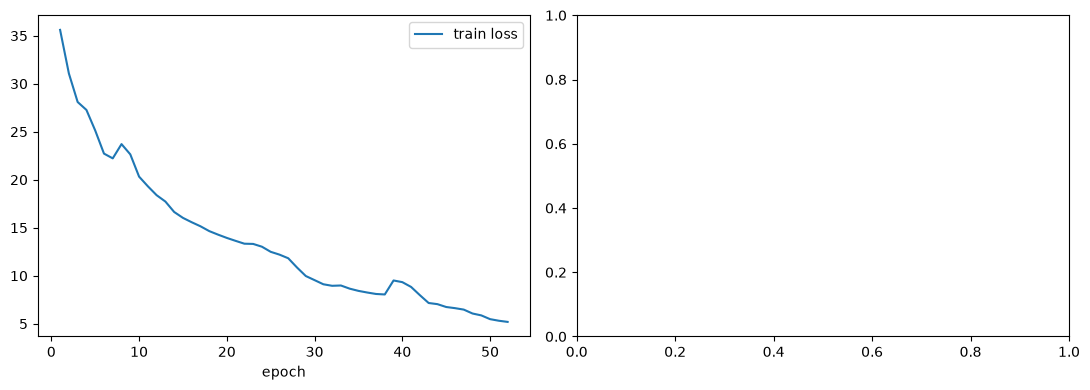

In [6]:
hist = pd.read_csv(RES / "models" / "seed7_history.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(hist.epoch, hist.train_loss, label="train loss")
if "val_loss" in hist: a1.plot(hist.epoch, hist.val_loss, label="val loss")
a1.set_xlabel("epoch"); a1.legend()
if "val_macro_f1" in hist:
    a2.plot(hist.epoch, hist.val_macro_f1, color="#009E73")
    b = hist.loc[hist.val_macro_f1.idxmax()]
    a2.scatter(b.epoch, b.val_macro_f1, color="red", zorder=3, label=f"best: epoch {int(b.epoch)}, {b.val_macro_f1:.3f}")
    a2.set_xlabel("epoch"); a2.set_ylabel("validation macro-F1"); a2.legend()
plt.tight_layout(); plt.show()

Early stopping keeps the best validation epoch. For this model it comes early (epoch 12 in the
published metrics), after which validation macro-F1 does not improve; training continues until patience
runs out.